In [21]:
import numpy as np
import pandas as pd

import scipy.stats as stats

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import accuracy_score
from sklearn.linear_model import LogisticRegression 
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import FunctionTransformer
from sklearn.compose import ColumnTransformer

In [2]:
df = pd.read_csv(r'Data/train.csv', usecols=['Age','Fare','Survived'])

In [3]:
df.sample(5)

,Survived,Age,Fare
829,1,62.0,80.0000
254,0,41.0,20.2125
859,0,NaN,7.2292
800,0,34.0,13.0000
787,0,8.0,29.1250


In [4]:
df.Age = df.Age.fillna(df.Age.mean())

In [5]:
df.Age.isna().sum()

np.int64(0)

In [6]:
X = df.iloc[:,1:3]
y = df.iloc[:,0]

In [7]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)

C:\Users\jaggi\AppData\Local\Temp\ipykernel_9752\645970104.py:3: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(X_train ['Age'])


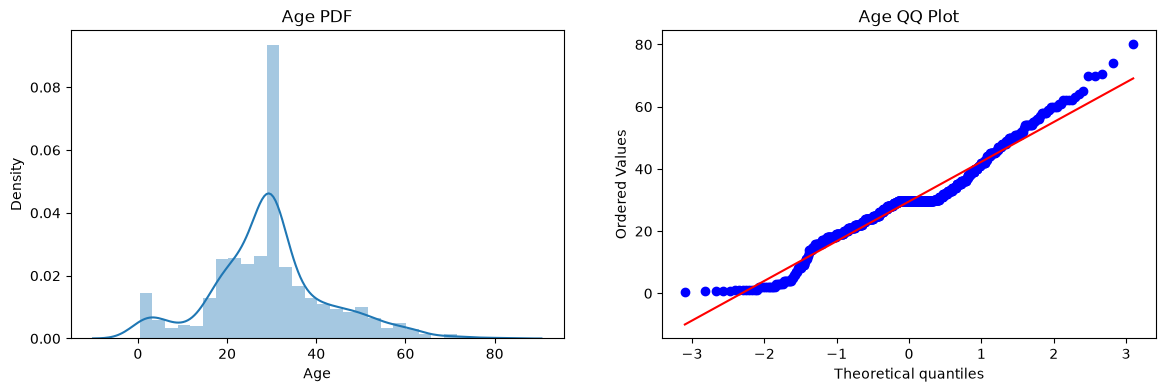

In [8]:
plt.figure(figsize=(14,4))
plt.subplot(121)
sns.distplot(X_train ['Age'])
plt.title('Age PDF')
plt.subplot(122)
stats.probplot(X_train ['Age'], dist="norm", plot=plt)
plt.title('Age QQ Plot')
plt.show()

C:\Users\jaggi\AppData\Local\Temp\ipykernel_9752\910029290.py:3: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(X_train ['Fare'])


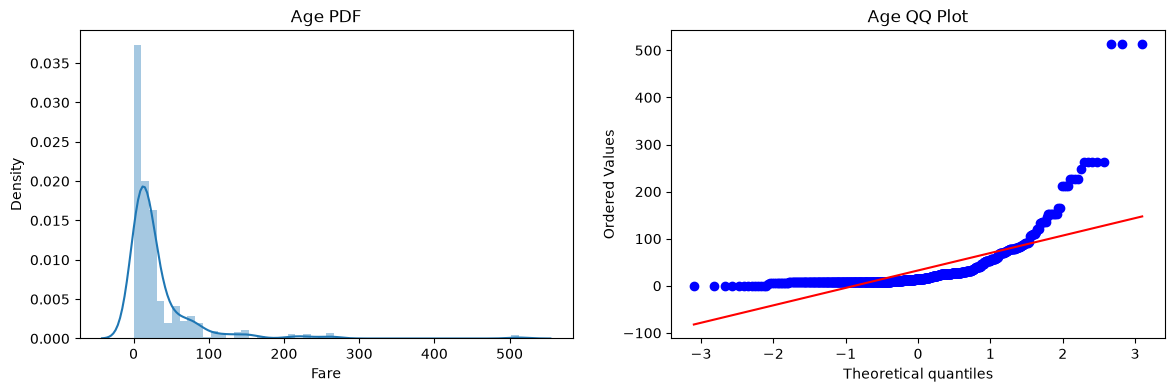

In [9]:
plt.figure(figsize=(14,4))
plt.subplot(121)
sns.distplot(X_train ['Fare'])
plt.title('Age PDF')
plt.subplot(122)
stats.probplot(X_train['Fare'], dist="norm", plot=plt)
plt.title('Age QQ Plot')
plt.show()

## Without Transformation

In [10]:
clf = LogisticRegression()
clf2 = DecisionTreeClassifier()

In [11]:
clf.fit(X_train,y_train)
clf2.fit(X_train, y_train)

y_pred = clf.predict(X_test)
y_pred1 = clf2.predict(X_test)

print("Accuracy LR", accuracy_score (y_test,y_pred))
print("Accuracy DT", accuracy_score(y_test,y_pred1))

Accuracy LR 0.6480446927374302
Accuracy DT 0.6871508379888268


## With Transformation

In [12]:
trf = FunctionTransformer(func = np.log1p)

In [13]:
X_train_transformed = trf.fit_transform(X_train)
X_test_transformed = trf.transform(X_test)

In [14]:
clf = LogisticRegression()
clf2 = DecisionTreeClassifier()

clf.fit(X_train_transformed,y_train)
clf2.fit(X_train_transformed, y_train)

y_pred = clf.predict(X_test_transformed)
y_pred1 = clf2.predict(X_test_transformed)

print("Accuracy LR", accuracy_score (y_test,y_pred))
print("Accuracy DT", accuracy_score(y_test,y_pred1))

Accuracy LR 0.6815642458100558
Accuracy DT 0.6759776536312849


In [15]:
# cross Verification
X_transformed = trf.fit_transform(X)
clf = LogisticRegression()
clf2 = DecisionTreeClassifier()
print("LR", np.mean(cross_val_score(clf, X_transformed, y, scoring='accuracy', cv = 10 )))
print("DT", np.mean(cross_val_score(clf2, X_transformed, y, scoring='accuracy', cv = 10 )))

LR 0.678027465667915
DT 0.6610861423220974


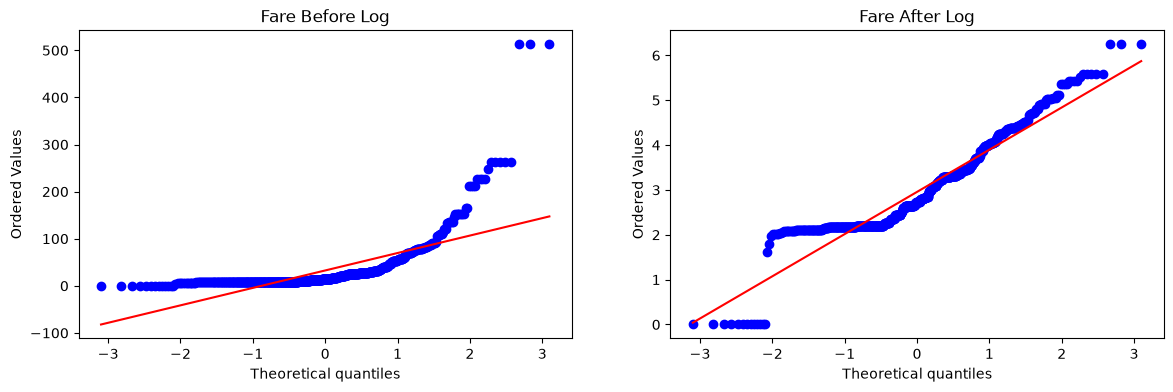

In [18]:
plt.figure(figsize=(14,4))
plt.subplot(121)
stats.probplot(X_train ['Fare'], dist="norm", plot=plt)
plt.title('Fare Before Log')
plt.subplot(122)
stats.probplot(X_train_transformed ['Fare'], dist="norm", plot=plt)
plt.title('Fare After Log')
plt.show()

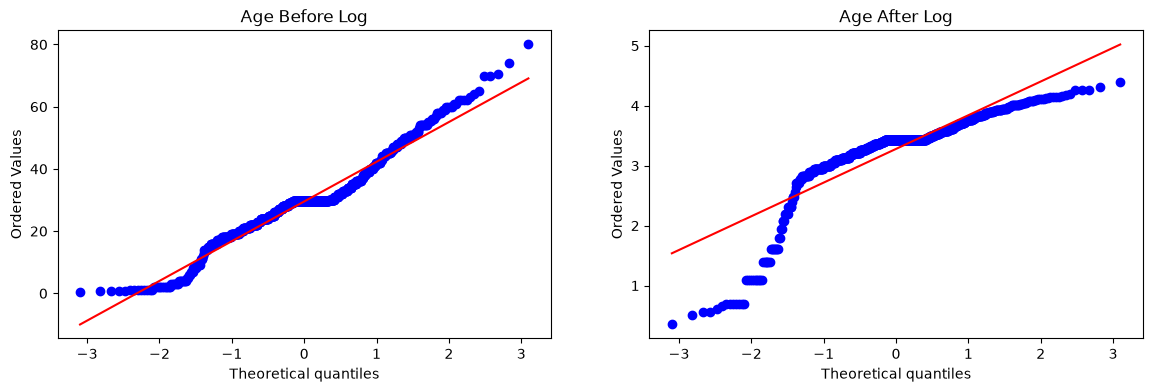

In [19]:
plt.figure(figsize=(14,4))
plt.subplot(121)
stats.probplot(X_train ['Age'], dist="norm", plot=plt)
plt.title('Age Before Log')
plt.subplot(122)
stats.probplot(X_train_transformed['Age'], dist="norm", plot=plt)
plt.title('Age After Log')
plt.show()

In [24]:
trf2 = ColumnTransformer([('log', FunctionTransformer(np.log1p), ['Fare'])], remainder = 'passthrough')

X_train_transformed2 = trf2.fit_transform(X_train)
X_test_transformed2 = trf2.transform(X_test)

clf = LogisticRegression()
clf2 = DecisionTreeClassifier()

clf.fit(X_train_transformed2, y_train)
clf2.fit(X_train_transformed2, y_train)

y_pred = clf.predict(X_test_transformed2)
y_pred1 = clf2.predict(X_test_transformed2)

print("Accuracy LR", accuracy_score (y_test,y_pred))
print("Accuracy DT", accuracy_score(y_test,y_pred1))

Accuracy LR 0.6703910614525139
Accuracy DT 0.664804469273743


In [25]:
# cross Verification
X_transformed2 = trf.fit_transform(X)
clf = LogisticRegression()
clf2 = DecisionTreeClassifier()
print("LR", np.mean(cross_val_score(clf, X_transformed2, y, scoring='accuracy', cv = 10 )))
print("DT", np.mean(cross_val_score(clf2, X_transformed2, y, scoring='accuracy', cv = 10 )))

LR 0.678027465667915
DT 0.6565792759051187


In [34]:
def apply_transform (transform):
    X = df.iloc[:,1:3]
    y = df.iloc[:,0]
    trf = ColumnTransformer ([('log', FunctionTransformer(transform), ['Fare'])], remainder='passthrough')
    X_trans = trf.fit_transform(X)
    
    clf = LogisticRegression()
    
    print("Accuracy", np.mean(cross_val_score (clf, X_trans, y, scoring='accuracy', cv=10)))
    
    plt.figure(figsize=(14,4))
    
    plt.subplot(121)
    stats.probplot(X['Fare'], dist="norm", plot=plt)
    plt.title('Fare Before Transform')
    
    plt.subplot(122)
    stats.probplot(X_trans[:,0], dist="norm", plot=plt)
    plt.title('Fare After Transform')
    plt.show()

Accuracy 0.6589013732833957


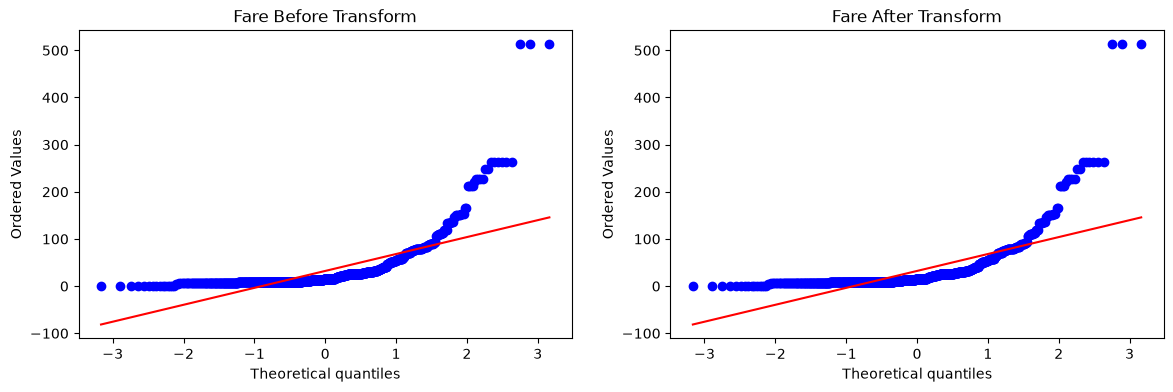

In [35]:
apply_transform(lambda X : X)

Accuracy 0.6431335830212235


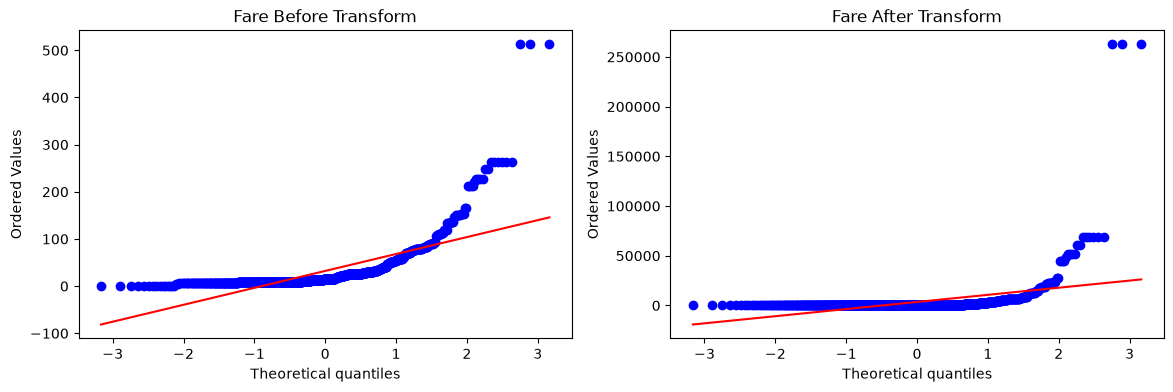

In [36]:
apply_transform(lambda X : X**2)

Accuracy 0.6262796504369538


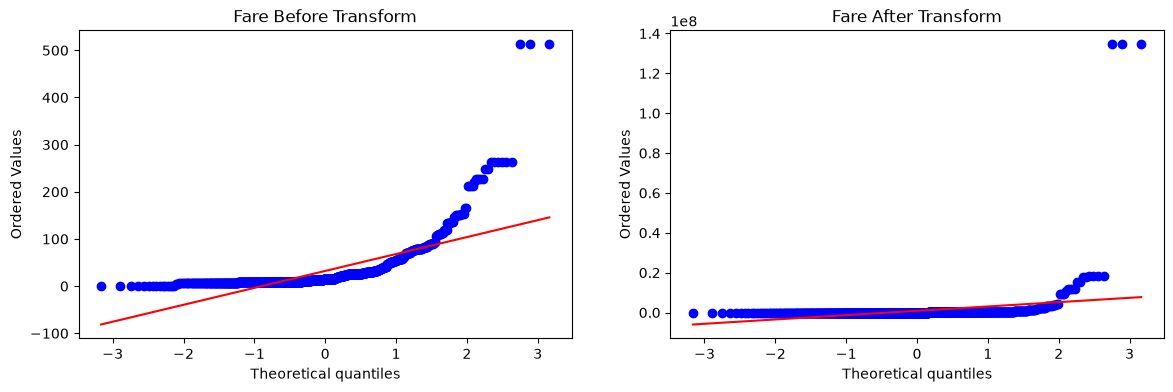

In [37]:
apply_transform(lambda X : X**3)